# k calculator: how many EXTRA rooms should we sell on a night?

The models (notebooks 03 to 05) only say *how likely* each booking is to cancel. The hotel needs a **number**: **k = how many rooms beyond capacity to keep selling on a given night.**

- Sell too few extra rooms and cancelled rooms stay **empty** (we lose that night's stay value).
- Sell too many and guests are **walked** to another hotel (EUR 300 each, and the client allows at most **10 walks per 1,000 arrivals**).

Two rules turn chances into *k*:

| Rule | Formula | Used for |
|---|---|---|
| **z-buffer** | `k = floor(expected − z × spread)` | our models |
| **margin** | `k = floor(expected) − margin` | the client's current (flat) rule |

- **expected** = the sum of the cancel chances of that night's bookings (the average number of cancels).
- **spread** = the standard deviation of that sum, so `z` is a **Z-score**: how many standard deviations below the average we hold back. `z = 0` resells exactly the expected cancels; `z > 0` is more cautious (fewer walks, more empty rooms). The buffer is never negative.
- The flat rule has no spread, so its buffer is a plain number of rooms.

**What this notebook does**

1. Defines the k functions (this replaces `src/k_calculator.py`).
2. Works through a tiny example you can check by hand.
3. Runs it on the real bookings: picks the cheapest safe buffer **on the choose period** for a model *and* for the client's flat rule, then compares them.
4. Runs the proof period once, only if you switch it on.

## 1. Set up

In [1]:
import importlib.util
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, log_loss,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

pd.set_option("display.max_colwidth", 130)
pd.set_option("display.width", 200)

# --- where is everything? (works whether Jupyter starts in notebooks/ or in the project root) ---
HERE = Path.cwd().resolve()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "notes" / "features_simple.py").exists())
NOTES, SRC = ROOT / "notes", ROOT / "src"
for folder in (NOTES, SRC):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import data               # the starter's data.py: reads hotels.csv (and downloads it if it is missing)
import features_simple    # our cleaning + the Bin 1 clue columns (known on the day of booking)


def load_contract():
    """Load the client's scoring file. We use it exactly as it is and never edit it."""
    for folder in (NOTES, SRC, SRC / "__pycache__"):
        path = folder / "contract.py"
        if path.exists():
            spec = importlib.util.spec_from_file_location("contract", path)
            module = importlib.util.module_from_spec(spec)
            spec.loader.exec_module(module)
            print("scoring file loaded from:", path.relative_to(ROOT))
            return module
    raise FileNotFoundError("contract.py was not found in notes/ or src/")


contract = load_contract()

# --- chart look: one blue line, one orange highlight, quiet grid, dark text ---
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10,
})

scoring file loaded from: src/__pycache__/contract.py


## 2. The k functions

These are the same functions as `src/k_calculator.py`:

| Function | What it does |
|---|---|
| `calculate_k(nights, buffer, kind)` | k for every night (`kind="z"` or `"margin"`), never below 0, whole rooms only |
| `buffer_label(buffer, kind)` | readable text such as `0.8 std devs`, so the unit is never a mystery |
| `avg_rooms_held_back(nights, buffer, kind)` | the buffer in rooms per night, so z and margin can be compared |
| `find_best_buffer(nights, kind)` | try many buffers and keep the **cheapest one inside the walk limit** (run on the choose period only) |
| `score_k(nights, k)` | euros, empty rooms, walked guests, walks per 1,000, limit met (the client's `contract.night_cost`) |
| `sweep_buffers`, `plot_buffer_sweep` | (extra, for the charts) the score of every buffer in the grid |

In [2]:
Z_GRID = [round(i * 0.1, 1) for i in range(0, 41)]   # 0.0 ... 4.0 (a buffer only holds rooms back)
MARGIN_GRID = list(range(0, 61))                       # 0 ... 60 rooms


def calculate_k(nights, buffer, kind="z"):
    """k = how many EXTRA rooms to sell on each night.
       kind="z"      -> k = floor(expected - z x spread). Used for the models.
       kind="margin" -> k = floor(expected) - margin.     Used for the client's flat rule."""
    if kind == "margin":
        k = np.floor(nights["expected"]) - buffer
    else:
        k = np.floor(nights["expected"] - buffer * nights["spread"])
    k = np.clip(k, 0, None)        # k is never below 0
    return k.astype(int)           # whole rooms only


def avg_rooms_held_back(nights, buffer, kind="z"):
    """The buffer expressed in rooms per night, so z and margin can be compared."""
    if kind == "margin":
        return float(buffer)
    return float(buffer * nights["spread"].mean())


def find_best_buffer(nights, kind="z"):
    """Try many buffers and keep the CHEAPEST one that stays inside the walk limit.
       Run this on the CHOOSE period only. Returns the buffer and its score."""
    buffers_to_try = MARGIN_GRID if kind == "margin" else Z_GRID
    best_buffer, best_result = None, None
    for buffer in buffers_to_try:
        result = contract.night_cost(nights, calculate_k(nights, buffer, kind))   # the starter scores it for us
        if result["ceiling_met"]:                                                 # only buffers inside the walk limit count
            if best_result is None or result["cost_eur"] < best_result["cost_eur"]:
                best_buffer, best_result = buffer, result
    if best_result is None:
        raise ValueError("No buffer stayed inside the walk limit. Try a bigger range of buffers.")
    if best_buffer in (buffers_to_try[0], buffers_to_try[-1]):
        print(f"   WARNING: best buffer {best_buffer} is at the edge of the grid; widen the grid.")
    return best_buffer, best_result


def sweep_buffers(nights, kind="z"):
    """The score of EVERY buffer in the grid (for the chart)."""
    grid = MARGIN_GRID if kind == "margin" else Z_GRID
    rows = [{"buffer": b, **contract.night_cost(nights, calculate_k(nights, b, kind))} for b in grid]
    return pd.DataFrame(rows)


def plot_buffer_sweep(sweep, best_buffer, xlabel, title):
    """Left: what each buffer costs. Right: how many guests it walks (the client allows at most 10 per 1,000).
       The grey zone is every buffer that breaks that limit; the orange dot is the cheapest buffer outside it."""
    fig, (ax_cost, ax_walk) = plt.subplots(1, 2, figsize=(11, 3.6))
    within = sweep[sweep["walks_per_1000"] <= contract.WALK_CEILING]
    edge = within["buffer"].min() if len(within) else sweep["buffer"].max()
    best = sweep.loc[sweep["buffer"] == best_buffer].iloc[0]

    ax_cost.plot(sweep["buffer"], sweep["cost_eur"] / 1e6, color=BLUE)
    ax_cost.plot(best_buffer, best["cost_eur"] / 1e6, "o", color=ORANGE, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
    ax_cost.annotate(f"cheapest safe buffer: {best_buffer}", (best_buffer, best["cost_eur"] / 1e6),
                     xytext=(10, -18), textcoords="offset points", color=MUTED)
    ax_cost.set_ylabel("cost on the choose period (EUR millions)")

    ax_walk.plot(sweep["buffer"], sweep["walks_per_1000"], color=BLUE)
    ax_walk.axhline(contract.WALK_CEILING, color=MUTED, linestyle="--", linewidth=1)
    ax_walk.annotate(f"client limit: {contract.WALK_CEILING:g} per 1,000", (sweep["buffer"].max(), contract.WALK_CEILING),
                     xytext=(0, 4), textcoords="offset points", ha="right", color=MUTED)
    ax_walk.plot(best_buffer, best["walks_per_1000"], "o", color=ORANGE, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
    ax_walk.set_ylabel("walked guests per 1,000 arrivals")

    for ax in (ax_cost, ax_walk):
        ax.axvspan(sweep["buffer"].min(), edge, color=GRID, alpha=0.6, zorder=0)
        ax.set_xlabel(xlabel)
    ax_cost.set_title(title + ": cost")
    ax_walk.set_title(title + ": walks")
    ax_cost.text(0.02, 0.96, "grey = breaks the walk limit", transform=ax_cost.transAxes, va="top", color=MUTED)
    fig.tight_layout()
    plt.show()


def buffer_label(buffer, kind="z"):
    """Readable text for the result table, so the unit is never a mystery."""
    if kind == "margin":
        return f"{buffer} rooms"
    return f"{buffer} std devs"


def score_k(nights, k):
    """Score a k: euros, empty rooms, walked guests, walks per 1,000, limit met."""
    return contract.night_cost(nights, k)

## 3. A tiny example you can check by hand

Two nights at one hotel (the same two nights as in `tests/test_contract.py`).

- **Night 1:** 4 bookings, each with a 50% chance of cancelling. Expected cancels = 4 × 0.5 = **2.0**. Spread = √(4 × 0.5 × 0.5) = **1.0**. Two really cancelled. Each stay is worth EUR 100 × 2 nights = EUR 200.
- **Night 2:** 2 bookings, each with a 10% chance. Nobody cancelled.

In [3]:
toy = pd.DataFrame({
    "hotel": ["City Hotel"] * 6,
    "arrival_date": pd.to_datetime(["2016-08-01"] * 4 + ["2016-08-02"] * 2),
    "is_canceled": [1, 1, 0, 0, 0, 0],
    "adr": [100.0] * 4 + [50.0] * 2,
    "nights": [2] * 4 + [1] * 2,
})
toy_chances = [0.5] * 4 + [0.1] * 2                      # our chance that each booking cancels
toy_nights = contract.nightly_table(toy, toy_chances)    # add the chances up per night
display(toy_nights.round(3))

rows = []
for z in (0, 1, 2):
    k = calculate_k(toy_nights, z)
    result = score_k(toy_nights, k)
    rows.append({"buffer": buffer_label(z), "k night 1": k.iloc[0], "k night 2": k.iloc[1],
                 "empty rooms": result["empty_rooms"], "walked guests": result["walked_guests"],
                 "cost EUR": result["cost_eur"]})
display(pd.DataFrame(rows).set_index("buffer"))

book  cancelled  expected  spread  stay_value
hotel      arrival_date                                               
City Hotel 2016-08-01       4          2       2.0   1.000       200.0
           2016-08-02       2          0       0.2   0.424        50.0

,k night 1,k night 2,empty rooms,walked guests,cost EUR
buffer,,,,,
0 std devs,2,0,0,0,0.0
1 std devs,1,0,1,0,200.0
2 std devs,0,0,2,0,400.0


**Check by hand.** With `z = 1`: night 1 has `k = floor(2.0 − 1 × 1.0) = 1`. Two guests cancelled but we resold only one room, so **1 room stays empty** and costs EUR 200. Night 2: `k = floor(0.2 − 1 × 0.42) = −1`, which is clipped to **0**.

`z = 0` costs nothing here only because exactly 2 cancelled, which is exactly what we expected. Real nights swing around their average, which is the reason for the buffer.

**The client's flat rule on the same night:** `k = floor(expected) − margin`. With a margin of 1 room, night 1 gives `floor(2.0) − 1 = 1`.

In [4]:
for margin in (0, 1, 2):
    print(f"margin {margin} room(s): k per night =", calculate_k(toy_nights, margin, kind="margin").tolist())

margin 0 room(s): k per night = [2, 0]
margin 1 room(s): k per night = [1, 0]
margin 2 room(s): k per night = [0, 0]


## 4. The real bookings

First the switch, then the same data loading as the model notebooks.

In [5]:
RUN_PROOF = False     # the proof period is the FINAL exam: leave this False until everything is decided

In [6]:
raw = data.read_raw()                                     # every booking, exactly as exported
bookings = features_simple.clean_bookings(raw)            # the documented cleaning choices
train, choose, proof = contract.split_periods(bookings)   # split by arrival date, as the contract says
train, choose, proof = [features_simple.add_features(part) for part in (train, choose, proof)]

FEATURES = features_simple.bin1_features                  # the clues known on the day of booking
NUMERIC = features_simple.bin1_numeric_cols
CATEGORICAL = features_simple.bin1_categorical_cols

print(f"bookings: train {len(train):,} | choose {len(choose):,} | proof {len(proof):,}")
print("The proof bookings are loaded but never looked at (no scores, no labels) until RUN_PROOF = True.")

bookings: train 49,108 | choose 29,482 | proof 40,619
The proof bookings are loaded but never looked at (no scores, no labels) until RUN_PROOF = True.


### A model to get chances from

*k* needs a chance for every booking. Here we use the logistic regression with its fixed default settings, trained on **train only**. Any other model works the same way: only `chances_choose` changes (see notebooks 03 to 05).

In [7]:
def make_preparer(scale_numbers):
    """Turn the clue columns into numbers. Everything it learns, it learns from the rows it is fitted on."""
    text_step = OneHotEncoder(handle_unknown="ignore", min_frequency=20)   # rare values are grouped together
    number_step = StandardScaler() if scale_numbers else "passthrough"
    return ColumnTransformer([
        ("text", text_step, CATEGORICAL),
        ("numbers", number_step, NUMERIC),
    ])


model = Pipeline([
    ("prepare", make_preparer(scale_numbers=True)),
    ("model", LogisticRegression(max_iter=1000)),
])
model.fit(train[FEATURES], train["is_canceled"])                 # learn from train only

chances_choose = model.predict_proba(choose[FEATURES])[:, 1]     # column 1 = chance of cancelling
nights_choose = contract.nightly_table(choose, chances_choose)   # one row per hotel and night
print(f"{len(nights_choose)} hotel-nights on the choose period; the chances add up to "
      f"{chances_choose.sum():,.0f} cancellations ({int(choose['is_canceled'].sum()):,} really happened)")

368 hotel-nights on the choose period; the chances add up to 9,433 cancellations (10,884 really happened)


## 5. Find the cheapest safe buffer on the choose period

`find_best_buffer` tries every buffer in the grid and keeps the **cheapest one that stays inside the walk limit**. A rule that saves more euros but breaks the limit is rejected. This is done on the **choose** period only, never on proof.

In [8]:
best_z, best_model = find_best_buffer(nights_choose, kind="z")
print(f"Model: best buffer = {buffer_label(best_z)} "
      f"= {avg_rooms_held_back(nights_choose, best_z):.1f} rooms held back per night on average")
print("   ", best_model)

Model: best buffer = 0.8 std devs = 2.4 rooms held back per night on average
    {'cost_eur': 1145881.19, 'empty_rooms': 2715, 'walked_guests': 179, 'walks_per_1000': 9.62, 'ceiling_met': True, 'nights': 368}


### The client's flat rule

Every saving is measured **against the client's flat rule**, never against selling nothing extra. The flat rule gives each booking its hotel's average cancellation rate from train, then holds back a fixed number of rooms (its margin, chosen on the choose period under the same walk limit).

In [9]:
# The client's flat rule is only a yardstick (it is not one of our models):
#   chance of cancelling = that hotel's cancellation rate in TRAIN, k = floor(rate x bookings) - margin.
# Every saving is measured against it, never against "sell nothing extra".
hotel_rate = train.groupby("hotel")["is_canceled"].mean()


def flat_rule_nights(df):
    chances = df["hotel"].map(hotel_rate).to_numpy()       # every booking gets its hotel's average rate
    return contract.nightly_table(df, chances)


flat_choose = flat_rule_nights(choose)
flat_margin, flat_best = find_best_buffer(flat_choose, kind="margin")
print(f"Client's flat rule: hotel rates from train {hotel_rate.round(3).to_dict()}")
print(f"Best safety margin on the choose period: {flat_margin} rooms  "
      f"(cost EUR {flat_best['cost_eur']:,.0f}, walks per 1,000 {flat_best['walks_per_1000']})")

Client's flat rule: hotel rates from train {'City Hotel': 0.417, 'Resort Hotel': 0.252}
Best safety margin on the choose period: 16 rooms  (cost EUR 2,416,541, walks per 1,000 9.25)


In [10]:
comparison = pd.DataFrame([
    {"rule": "client's flat rule", "buffer": buffer_label(flat_margin, "margin"),
     "avg rooms held back": avg_rooms_held_back(flat_choose, flat_margin, "margin"),
     "cost EUR": flat_best["cost_eur"], "empty rooms": flat_best["empty_rooms"],
     "walked guests": flat_best["walked_guests"], "walks per 1,000": flat_best["walks_per_1000"],
     "limit met": flat_best["ceiling_met"], "saving vs flat rule EUR": 0.0},
    {"rule": "model + z-buffer", "buffer": buffer_label(best_z),
     "avg rooms held back": avg_rooms_held_back(nights_choose, best_z),
     "cost EUR": best_model["cost_eur"], "empty rooms": best_model["empty_rooms"],
     "walked guests": best_model["walked_guests"], "walks per 1,000": best_model["walks_per_1000"],
     "limit met": best_model["ceiling_met"], "saving vs flat rule EUR": flat_best["cost_eur"] - best_model["cost_eur"]},
]).set_index("rule")
display(comparison.round(2))

,buffer,avg rooms held back,cost EUR,empty rooms,walked guests,"walks per 1,000",limit met,saving vs flat rule EUR
rule,,,,,,,,
client's flat rule,16 rooms,16.00,2416540.66,5529,172,9.25,True,0.00
model + z-buffer,0.8 std devs,2.44,1145881.19,2715,179,9.62,True,1270659.47


### Cost and walks for every buffer

Grey = buffers that break the walk limit (not allowed, even if cheaper). Orange dot = the cheapest buffer outside the grey zone. If the dot sits at the edge of the grid, `find_best_buffer` prints a warning to widen the grid.

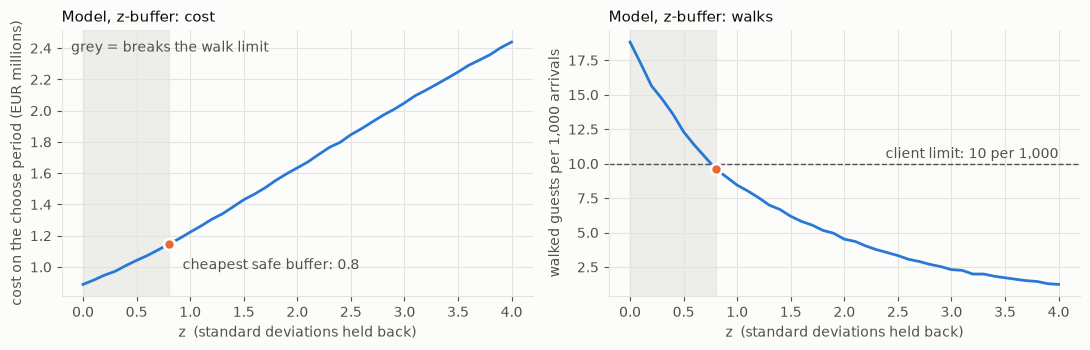

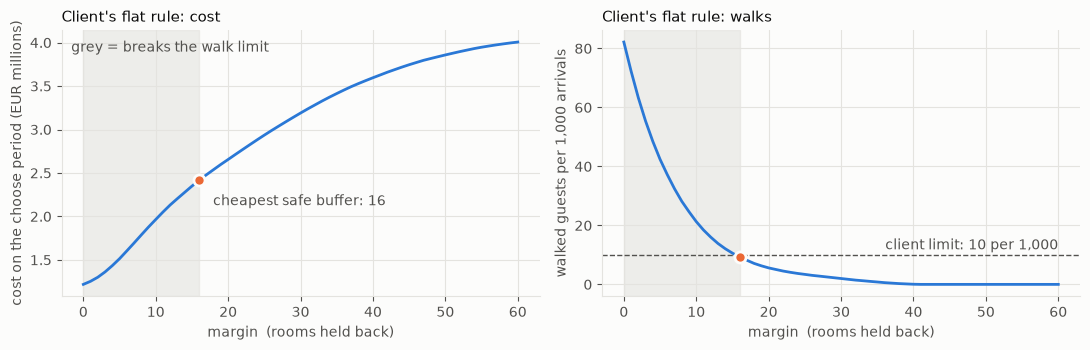

In [11]:
plot_buffer_sweep(sweep_buffers(nights_choose, "z"), best_z, "z  (standard deviations held back)", "Model, z-buffer")
plot_buffer_sweep(sweep_buffers(flat_choose, "margin"), flat_margin, "margin  (rooms held back)", "Client's flat rule")

### What the revenue manager would read

The first few hotel-nights with the oversell count *k* from the model's buffer. (`src/nightly.py` does this for the next 14 nights.)

In [12]:
view = nights_choose.assign(oversell_k=calculate_k(nights_choose, best_z))
display(view[["book", "cancelled", "expected", "spread", "oversell_k"]].round(1).head(10))

book  cancelled  expected  spread  oversell_k
hotel      arrival_date                                               
City Hotel 2016-07-01     141         68      71.3     4.3          67
           2016-07-02      80         33      25.0     3.7          22
           2016-07-03      84         21      24.6     3.8          21
           2016-07-04      92         30      26.3     3.7          23
           2016-07-05      73         14      25.0     3.5          22
           2016-07-06     153         77      81.0     4.0          77
           2016-07-07     135         77      65.7     4.2          62
           2016-07-08     101         32      30.9     4.2          27
           2016-07-09      91         27      37.3     4.2          33
           2016-07-10      76         12      21.6     3.4          18

## 6. Proof: the final exam (run once, at the very end)

We apply the **buffers chosen above, unchanged**, to the proof period (1 January to 31 August 2017) and report euros, rooms and walks side by side, as the contract requires. Set `RUN_PROOF = True` only when everything else is final. If you change anything after seeing this result, the contract says to report both runs.

In [13]:
if not RUN_PROOF:
    print("RUN_PROOF is False, so the proof period was NOT used. Set it to True for the final run.")
else:
    chances_proof = model.predict_proba(proof[FEATURES])[:, 1]
    nights_proof = contract.nightly_table(proof, chances_proof)
    model_proof = score_k(nights_proof, calculate_k(nights_proof, best_z))

    flat_nights_proof = flat_rule_nights(proof)
    flat_proof = score_k(flat_nights_proof, calculate_k(flat_nights_proof, flat_margin, "margin"))

    display(pd.DataFrame([
        {"rule": "client's flat rule", "buffer": buffer_label(flat_margin, "margin"),
         "cost EUR": flat_proof["cost_eur"], "empty rooms": flat_proof["empty_rooms"],
         "walked guests": flat_proof["walked_guests"], "walks per 1,000": flat_proof["walks_per_1000"],
         "limit met": flat_proof["ceiling_met"], "saving vs flat rule EUR": 0.0},
        {"rule": "model + z-buffer", "buffer": buffer_label(best_z),
         "cost EUR": model_proof["cost_eur"], "empty rooms": model_proof["empty_rooms"],
         "walked guests": model_proof["walked_guests"], "walks per 1,000": model_proof["walks_per_1000"],
         "limit met": model_proof["ceiling_met"], "saving vs flat rule EUR": flat_proof["cost_eur"] - model_proof["cost_eur"]},
    ]).set_index("rule").round(2))

RUN_PROOF is False, so the proof period was NOT used. Set it to True for the final run.
